In [5]:
# Data cleaning
import pandas as pd
import matplotlib as mpt
from pathlib import Path

ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA = ROOT / "data"

# print(ROOT)

# Load raw files to clean
price = pd.read_csv( DATA / "raw" / "price_raw.csv")

onchain = pd.read_csv( DATA / "raw" / "onchain_raw.csv")


date     0
open     0
high     0
low      0
close    0
dtype: int64
date                 0
active_addresses     1
mvrv                 1
transaction_fees     1
hash_rate            1
transaction_count    1
dtype: int64
DatetimeIndex([], dtype='datetime64[us, UTC]', freq='D')


,date,active_addresses,mvrv,transaction_fees,hash_rate,transaction_count
3096,2026-05-24 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN


Empty DataFrame
Columns: [date, open, high, low, close]
Index: []
Empty DataFrame
Columns: [date, active_addresses, mvrv, transaction_fees, hash_rate, transaction_count]
Index: []
Empty DataFrame
Columns: [date, open, high, low, close]
Index: []
                open           high            low          close
count    3294.000000    3294.000000    3294.000000    3294.000000
mean    40465.579648   41285.072043   39577.224848   40482.861242
std     32549.684292   33047.215086   32013.160531   32546.437088
min      3211.710000    3276.500000    3156.260000    3211.720000
25%      9989.947500   10305.092500    9656.250000   10007.285000
50%     30287.075000   30782.850000   29638.700000   30291.730000
75%     64143.357500   65271.590000   62986.770000   64143.357500
max    124658.540000  126199.630000  123084.000000  124658.540000
       active_addresses         mvrv  transaction_fees     hash_rate  \
count      3.096000e+03  3096.000000       3096.000000  3.096000e+03   
mean       8.221

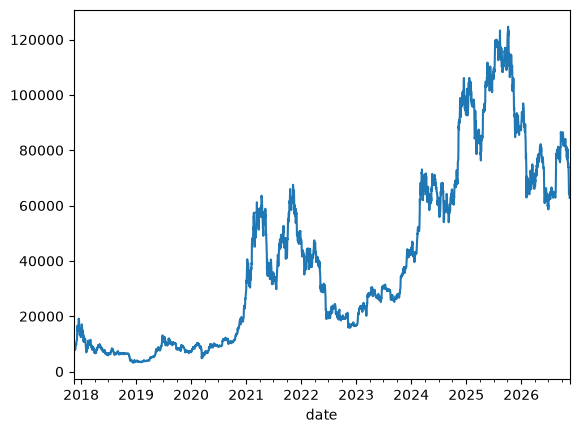

In [6]:
# Rename Coin Metrics 'time' to 'date
onchain = onchain.rename(columns={"time": "date"})

price["date"] = pd.to_datetime(
    price["date"],
    format="%Y-%m-%d",
    utc=True,
    errors="raise"
)

onchain["date"] = pd.to_datetime(
    onchain["date"],
    format="%Y-%m-%d",
    utc=True,
    errors="raise"
)

price = price.sort_values("date")
onchain = onchain.sort_values("date")

### Check missing values ###

# Determine how many missing in each col
print(price.isna().sum())
print(onchain.isna().sum())

# Determine how many dates are missing entirely.
expected_dates = pd.date_range(
    start=price["date"].min(),
    end=price["date"].max(),
    freq="D"
)

missing_dates = expected_dates.difference(price["date"])

print(missing_dates)

# Identify missing on chain observation
display(onchain[onchain.isna().any(axis=1)])

# Remove missing value (only 1 exists)
onchain = onchain.dropna().copy()

# Identify duplicates
print(price[price.duplicated("date", keep=False)])
print(onchain[onchain.duplicated("date", keep=False)])

# Remove identical observations
price = price.drop_duplicates()
onchain = onchain.drop_duplicates()

# Identify invalid values
invalid_prices = price[
    (price["open"] <= 0) | 
    (price["close"] <= 0) | 
    (price["high"] <= 0) |
    (price["low"] <= 0) |
    (price["high"] < price[["open", "close", "low"]].max(axis=1)) |
    (price["low"] > price[["open", "close", "low"]].min(axis=1))
]

print(invalid_prices)

# Check outliers
print(price.describe())
print(onchain.describe())

price.set_index("date")["close"].plot()

# Standardize reporting frequency by reindexing datasets to a complete daily calendar -- shifting by one row means shifting by one day
price = price.set_index("date").asfreq("D")
onchain = onchain.set_index("date").asfreq("D")

In [7]:
# Combine historical price and onchain data in 1 file and check it

combined = pd.merge(
    price,
    onchain,
    on="date",
    how="left",
    validate="one_to_one"
)

# Verify
print(combined.shape)

print(combined.head())

print(combined.isna().sum())

# Check duplicates
print(combined.columns)

(3294, 9)
                              open     high      low    close  \
date                                                            
2017-11-13 00:00:00+00:00  5839.94  6697.47  5699.99  6465.99   
2017-11-14 00:00:00+00:00  6465.99  6684.98  6311.07  6574.99   
2017-11-15 00:00:00+00:00  6575.99  7298.00  6575.99  7240.06   
2017-11-16 00:00:00+00:00  7240.14  7940.00  7076.00  7864.50   
2017-11-17 00:00:00+00:00  7876.98  7989.00  7451.00  7699.19   

                           active_addresses  mvrv  transaction_fees  \
date                                                                  
2017-11-13 00:00:00+00:00               NaN   NaN               NaN   
2017-11-14 00:00:00+00:00               NaN   NaN               NaN   
2017-11-15 00:00:00+00:00               NaN   NaN               NaN   
2017-11-16 00:00:00+00:00               NaN   NaN               NaN   
2017-11-17 00:00:00+00:00               NaN   NaN               NaN   

                           hash_rate

In [8]:
from pathlib import Path

# Save local copies of cleaned data
# Save local copy
cleaned_dir = DATA / "cleaned"
cleaned_dir.mkdir(parents=True, exist_ok=True)

price.to_csv(cleaned_dir / "price_cleaned.csv", index=True, index_label="date")

onchain.to_csv(cleaned_dir / "onchain_cleaned.csv", index=True, index_label="date")

combined.to_csv(cleaned_dir / "combined.csv",index=False)